# Mammarenavirus GPC residue patterns associated with LASV neutralization

**Goal:** use natural sequence variation across mammarenavirus glycoprotein-derived PhIP-Seq peptides to identify **residue identities/motifs associated with stronger LASV neutralization** in Lassa fever survivors.

This is a **hypothesis-generating residue analysis**. A residue emerging here is *neutralization-associated*, not proven to be functionally critical. Causal validation would require targeted peptide substitutions, competition, mutagenesis, or monoclonal-antibody experiments.

### Analysis logic
1. Use baseline Lassa fever survivors with matched neutralization data.
2. Restrict PhIP-Seq to **Mammarenavirus glycoprotein/GPC peptides**.
3. Map peptide sequences to the LASV Josiah GPC reference using local protein alignment.
4. Focus on peptides mapping to a user-defined neutralization-associated GPC window (default: GP2, residues 260–491; optionally narrow this after inspecting your LASV hits).
5. For each peptide, estimate whether peptide recognition is associated with higher neutralization.
6. Project each peptide's amino acids onto Josiah coordinates.
7. At each coordinate, test whether specific amino-acid identities among **reactive peptide observations** are associated with neutralization potency.
8. Require sufficient sequence variation/support and BH-FDR correct the residue-level tests.

The key idea is to exploit natural mammarenavirus sequence variation as a first-pass structure–function screen.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices

warnings.filterwarnings('ignore')

# ---------- paths ----------
LONG_FILE = Path('./output_files/long_spec_0_98_111226.csv')
META_FILE = Path('./metadata_files/master_sample_metadata_111226.csv')
REF_FASTA = Path('./ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta')
OUTDIR = Path('./output_figures/residue_neutralization')
OUTDIR.mkdir(parents=True, exist_ok=True)

SURVIVOR_COLOR = '#D55E00'

plt.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})

## 1. Load data and define baseline survivors

In [2]:
df = pd.read_csv(LONG_FILE)
sample_meta = pd.read_csv(META_FILE)

sample_meta['collection_date'] = pd.to_datetime(sample_meta['collection_date'], errors='coerce')

sample_meta_baseline = (
    sample_meta
    .sort_values(['participant_id', 'collection_date'])
    .drop_duplicates('participant_id', keep='first')
    .copy()
)

survivors = sample_meta_baseline.loc[
    sample_meta_baseline['Category'].eq('S')
].copy()

for c in ['Neut_Percent', 'GP_Calc_Conc', 'age_years', 'years_since_discharge']:
    survivors[c] = pd.to_numeric(survivors[c], errors='coerce')

print('Baseline survivors in metadata:', survivors['participant_id'].nunique())
print('With neutralization:', survivors['Neut_Percent'].notna().sum())
print('PhIP long columns:', df.columns.tolist())

Baseline survivors in metadata: 125
With neutralization: 125
PhIP long columns: ['peptide', 'individual', 'z_score', 'rpk', 'sequence', 'species', 'genus', 'family', 'protein_std', 'accession', 'cohort', 'category', 'reactive']


## 2. Restrict to baseline survivor PhIP samples and Mammarenavirus glycoprotein peptides

In [3]:
survivor_ids = set(survivors['sample_id'].dropna().astype(str))

phip_surv = df.loc[df['individual'].astype(str).isin(survivor_ids)].copy()

meta_cols = [
    'sample_id','participant_id','Neut_Percent','GP_Calc_Conc',
    'age_years','years_since_discharge','sex'
]
phip_surv = phip_surv.merge(
    survivors[meta_cols],
    left_on='individual', right_on='sample_id',
    how='left', validate='many_to_one'
)

# Mammarenavirus + glycoprotein/GPC only.
# genus naming can vary; family/genus checks are intentionally permissive.
mammagpc = phip_surv.loc[
    (
        phip_surv['genus'].astype(str).str.contains('Mammarenavirus', case=False, na=False)
        | phip_surv['species'].astype(str).str.contains('Mammarenavirus', case=False, na=False)
    )
    & phip_surv['protein_std'].astype(str).str.lower().eq('glycoprotein')
].copy()

mammagpc['reactive'] = mammagpc['reactive'].astype(bool)
mammagpc['Neut_Percent'] = pd.to_numeric(mammagpc['Neut_Percent'], errors='coerce')

print('Baseline survivor PhIP samples:', phip_surv['individual'].nunique())
print('Mammarenavirus GPC peptides:', mammagpc['peptide'].nunique())
print('Survivors represented:', mammagpc['individual'].nunique())
print()
print('Top species:')
print(mammagpc[['species','peptide']].drop_duplicates()['species'].value_counts().head(20))

Baseline survivor PhIP samples: 118
Mammarenavirus GPC peptides: 100
Survivors represented: 118

Top species:
species
Mammarenavirus lassaense             16
Mammarenavirus choriomeningitidis    13
Mammarenavirus whitewaterense         9
Mammarenavirus lunaense               6
Mammarenavirus bearense               4
Mammarenavirus mopeiaense             4
Mammarenavirus mafigaense             3
Pannonia mammarenavirus               3
Mammarenavirus lunkense               2
Mammarenavirus tacaribeense           2
Mammarenavirus ngerengerense          2
Mammarenavirus songeaense             2
Mammarenavirus marientalense          2
Mammarenavirus loeiense               2
Mammarenavirus wenzhouense            2
Mammarenavirus solweziense            2
Mammarenavirus ippyense               2
Mammarenavirus kitaleense             2
Mammarenavirus brazilense             2
Mammarenavirus juninense              2
Name: count, dtype: int64


## 3. Load Josiah GPC reference

The FASTA headers can vary. The cell below first tries to identify the GPC record from the description. If it cannot, inspect the printed records and set `GPC_RECORD_ID` manually.

In [4]:
records = list(SeqIO.parse(REF_FASTA, 'fasta'))
for i, r in enumerate(records):
    print(i, r.id, len(r.seq), r.description)

# Try automatic selection by header keywords.
gpc_candidates = [
    r for r in records
    if any(k in r.description.lower() for k in ['glycoprotein', 'glycoprotein precursor', 'gpc'])
]

if len(gpc_candidates) == 1:
    gpc_record = gpc_candidates[0]
elif len(gpc_candidates) > 1:
    # LASV GPC is ~491 aa; choose candidate closest to this length.
    gpc_record = sorted(gpc_candidates, key=lambda r: abs(len(r.seq)-491))[0]
else:
    raise ValueError('Could not automatically identify GPC record. Inspect printed FASTA records and select it manually.')

gpc_ref = str(gpc_record.seq).upper()
print()
print('Selected GPC:', gpc_record.id, len(gpc_ref), gpc_record.description)

0 sp|O09705|L_LASSJ 2218 sp|O09705|L_LASSJ RNA-directed RNA polymerase L OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=L PE=3 SV=1
1 sp|O73557|Z_LASSJ 99 sp|O73557|Z_LASSJ RING finger protein Z OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=Z PE=1 SV=4
2 sp|P08669|GLYC_LASSJ 491 sp|P08669|GLYC_LASSJ Pre-glycoprotein polyprotein GP complex OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=GPC PE=1 SV=1
3 sp|P13699|NCAP_LASSJ 569 sp|P13699|NCAP_LASSJ Nucleoprotein OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=N PE=1 SV=1

Selected GPC: sp|P08669|GLYC_LASSJ 491 sp|P08669|GLYC_LASSJ Pre-glycoprotein polyprotein GP complex OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=GPC PE=1 SV=1


## 4. Align mammarenavirus GPC peptides to Josiah GPC

In [5]:
aligner = PairwiseAligner()
aligner.mode = 'local'
aligner.substitution_matrix = substitution_matrices.load('BLOSUM62')
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5


def map_peptide_with_residues(peptide_seq, reference_seq=gpc_ref):
    """Map a peptide to Josiah GPC and retain peptide-AA -> reference-position pairs."""
    pep = str(peptide_seq).upper()
    alns = aligner.align(reference_seq, pep)
    if len(alns) == 0:
        return None
    aln = alns[0]
    ref_blocks, pep_blocks = aln.aligned
    if len(ref_blocks) == 0:
        return None

    pairs = []
    for (rs, re), (ps, pe) in zip(ref_blocks, pep_blocks):
        # Blocks are ungapped aligned stretches. They should have equal length.
        L = min(re-rs, pe-ps)
        for k in range(L):
            pairs.append((int(rs+k+1), pep[int(ps+k)]))

    if not pairs:
        return None

    return {
        'ref_start': min(p for p, aa in pairs),
        'ref_end': max(p for p, aa in pairs),
        'alignment_score': float(aln.score),
        'aligned_length': len(pairs),
        'residue_pairs': pairs,
    }

unique_peps = mammagpc[['peptide','sequence','species','accession']].drop_duplicates('peptide').copy()
map_rows = []
for _, r in unique_peps.iterrows():
    m = map_peptide_with_residues(r['sequence'])
    if m is not None:
        map_rows.append({**r.to_dict(), **m})

pep_map = pd.DataFrame(map_rows)
pep_map['peptide_length'] = pep_map['sequence'].astype(str).str.len()
pep_map['alignment_fraction'] = pep_map['aligned_length'] / pep_map['peptide_length']

print('Mapped peptides:', len(pep_map), '/', unique_peps['peptide'].nunique())
display(pep_map[['species','ref_start','ref_end','alignment_score','aligned_length','alignment_fraction']].describe(include='all'))

Mapped peptides: 100 / 100


,species,ref_start,ref_end,alignment_score,aligned_length,alignment_fraction
count,100,100.000000,100.000000,100.00000,100.00000,100.000000
unique,38,NaN,NaN,NaN,NaN,NaN
top,Mammarenavirus lassaense,NaN,NaN,NaN,NaN,NaN
freq,16,NaN,NaN,NaN,NaN,NaN
mean,NaN,302.920000,346.290000,187.19000,44.27000,0.962391
std,NaN,86.297896,87.563114,39.74094,4.96626,0.107962
min,NaN,58.000000,103.000000,27.00000,11.00000,0.239130
25%,NaN,286.000000,327.000000,171.75000,45.00000,0.978261
50%,NaN,298.000000,343.000000,189.00000,46.00000,1.000000
75%,NaN,369.000000,414.000000,213.75000,46.00000,1.000000


## 5. Choose the homologous GPC window

Start broadly with **GP2 (260–491)**. After inspecting your LASV neutralization-positive hits, you can narrow `REGION_START`/`REGION_END` to the actual associated cluster (for example, ~300–420) and rerun. Narrowing based on the LASV discovery result is appropriate as a *follow-up hypothesis-generating analysis*, but report that it was targeted rather than genome-wide.

In [6]:
REGION_START = 260
REGION_END = len(gpc_ref)  # 491 for Josiah GPC
MIN_ALIGNMENT_FRACTION = 0.60
MIN_REGION_OVERLAP_AA = 12

pep_map['region_overlap'] = (
    np.minimum(pep_map['ref_end'], REGION_END)
    - np.maximum(pep_map['ref_start'], REGION_START)
    + 1
).clip(lower=0)

region_peps = pep_map.loc[
    (pep_map['alignment_fraction'] >= MIN_ALIGNMENT_FRACTION)
    & (pep_map['region_overlap'] >= MIN_REGION_OVERLAP_AA)
].copy()

print('Mapped mammarenavirus GPC peptides in target window:', len(region_peps))
print('Species represented:', region_peps['species'].nunique())
display(region_peps[['species','ref_start','ref_end','alignment_fraction']].sort_values(['ref_start','species']).head(30))

Mapped mammarenavirus GPC peptides in target window: 89
Species represented: 36


,species,ref_start,ref_end,alignment_fraction
38,Mammarenavirus guanaritoense,268,313,1.000000
43,Mammarenavirus lunaense,277,322,1.000000
1,Mammarenavirus mopeiaense,279,323,0.978261
83,Mammarenavirus mopeiaense,279,323,0.978261
97,Mammarenavirus mopeiaense,279,323,0.978261
73,Mammarenavirus wenzhouense,280,325,1.000000
40,Mammarenavirus brazilense,282,326,0.978261
96,Mammarenavirus brazilense,282,326,0.978261
71,Pannonia mammarenavirus,282,323,0.913043
16,Mammarenavirus tacaribeense,284,329,1.000000


## 6. Peptide-level neutralization association across mammarenavirus GPC

This is useful context before residue testing. For each peptide, compare neutralization among peptide-reactive versus peptide-nonreactive survivors. FDR is corrected across the mapped target-window peptides. Positive `delta_median_neut` means recognition is associated with **higher** neutralization.

In [7]:
target_ids = set(region_peps['peptide'])
target_long = mammagpc.loc[mammagpc['peptide'].isin(target_ids)].copy()

rows=[]
for peptide, g in target_long.groupby('peptide'):
    g = g[['individual','reactive','Neut_Percent']].drop_duplicates('individual').dropna(subset=['Neut_Percent'])
    pos = g.loc[g['reactive'], 'Neut_Percent']
    neg = g.loc[~g['reactive'], 'Neut_Percent']
    if len(pos) < 3 or len(neg) < 3:
        continue
    _, p = mannwhitneyu(pos, neg, alternative='two-sided')
    rows.append({
        'peptide': peptide,
        'n_reactive': len(pos),
        'n_nonreactive': len(neg),
        'median_neut_reactive': pos.median(),
        'median_neut_nonreactive': neg.median(),
        'delta_median_neut': pos.median()-neg.median(),
        'p_peptide': p,
    })

peptide_assoc = pd.DataFrame(rows)
if len(peptide_assoc):
    peptide_assoc['FDR_peptide'] = multipletests(peptide_assoc['p_peptide'], method='fdr_bh')[1]
    peptide_assoc = peptide_assoc.merge(
        region_peps[['peptide','species','sequence','ref_start','ref_end']], on='peptide', how='left'
    )
    peptide_assoc = peptide_assoc.sort_values(['FDR_peptide','delta_median_neut'], ascending=[True,False])

display(peptide_assoc.head(30))

,peptide,n_reactive,n_nonreactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,p_peptide,FDR_peptide,species,sequence,ref_start,ref_end
26,AZI96412.1|precursor|Mammarenavirus_lassaense|...,31,87,86.988617,65.452147,21.536470,2.281017e-08,0.000002,Mammarenavirus lassaense,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,347,392
24,AZI96059.1|precursor|Mammarenavirus_lassaense|...,33,85,86.533287,65.563298,20.969990,4.045239e-07,0.000018,Mammarenavirus lassaense,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,346,391
27,AZI96476.1|precursor|Mammarenavirus_lassaense|...,37,81,86.166650,67.722491,18.444158,1.100137e-06,0.000033,Mammarenavirus lassaense,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,347,392
29,AZI96488.1|precursor|Mammarenavirus_lassaense|...,37,81,85.841573,67.242783,18.598790,3.775321e-06,0.000084,Mammarenavirus lassaense,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,347,392
52,WDY78991.1|precursor|Mammarenavirus_choriomeni...,42,76,85.282649,63.994275,21.288375,4.815203e-06,0.000086,Mammarenavirus choriomeningitidis,GNTAVAKCNINHDEEFCDMLRLIDYNKAALKKFKEDVESALHLFKT,294,336
18,AHC95553.1|precursor|Mammarenavirus_lassaense|...,24,94,87.618931,68.569823,19.049108,6.488869e-06,0.000096,Mammarenavirus lassaense,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,380,425
64,XOB76283.1|precursor|Yunnan_rodent_mammarenavi...,33,85,85.841573,67.242783,18.598790,8.618890e-06,0.000110,Yunnan rodent mammarenavirus 1,AKCNEKHDSEFCDMLRLFDFNKEAIKRLKIEANKSLNLITKAVNSL,299,344
23,ANH09740.1|precursor|Mammarenavirus_lassaense|...,49,69,84.984398,64.203796,20.780602,1.521094e-05,0.000147,Mammarenavirus lassaense,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,301,346
57,XBA96065.1|precursor|Mammarenavirus_lassaense|...,52,66,84.484379,63.994275,20.490105,1.446256e-05,0.000147,Mammarenavirus lassaense,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,300,345
40,UBB42231.1|precursor|Wenzhou_Suncus_murinus_ma...,40,78,85.388515,65.507722,19.880792,1.835515e-05,0.000147,Wenzhou Suncus murinus mammarenavirus 1,AKCNEKHDSEFCDMLRLFDFNREAIKRLRIEANKSTNLITSAVNSL,299,344


## 7. Build residue-level observations

A residue-level observation is created only when a survivor is **reactive to a peptide**. This asks: among recognized homologous mammarenavirus peptides, is recognition of a peptide carrying amino acid X at Josiah-aligned position Y associated with higher neutralization than recognition of peptides carrying other residues at that position?

Because a survivor can recognize multiple peptides, these observations are not fully independent. Therefore this screen is **exploratory** and should be used to nominate residues/motifs, not to claim causal residues. The later summary also includes a participant-collapsed sensitivity analysis.

In [8]:
map_lookup = region_peps.set_index('peptide')['residue_pairs'].to_dict()
meta_lookup = region_peps.set_index('peptide')[['species','sequence']].to_dict('index')

reactive_long = target_long.loc[target_long['reactive'] & target_long['Neut_Percent'].notna()].copy()

res_rows=[]
for _, r in reactive_long.iterrows():
    pairs = map_lookup.get(r['peptide'], [])
    for pos, aa in pairs:
        if REGION_START <= pos <= REGION_END:
            res_rows.append({
                'individual': r['individual'],
                'peptide': r['peptide'],
                'species': meta_lookup[r['peptide']]['species'],
                'position': pos,
                'aa': aa,
                'Neut_Percent': r['Neut_Percent'],
            })

res_obs = pd.DataFrame(res_rows)
print('Reactive peptide-residue observations:', len(res_obs))
print('Individuals:', res_obs['individual'].nunique())
print('Positions covered:', res_obs['position'].nunique())
print('Species:', res_obs['species'].nunique())

Reactive peptide-residue observations: 101850
Individuals: 112
Positions covered: 191
Species: 36


## 8. Residue identity screen

For each Josiah-aligned position and amino-acid identity, compare neutralization for reactive observations carrying that residue versus reactive observations carrying an alternative residue at the same position.

Filters:
- at least `MIN_CARRIERS` unique survivors carrying the residue,
- at least `MIN_ALTERNATIVE` unique survivors represented among alternative residues,
- at least two amino-acid states at the position.

FDR correction is performed across all tested position/residue hypotheses.

In [9]:
MIN_CARRIERS = 5
MIN_ALTERNATIVE = 5

res_tests=[]
for pos, gp in res_obs.groupby('position'):
    if gp['aa'].nunique() < 2:
        continue
    for aa, gaa in gp.groupby('aa'):
        carriers = gaa.groupby('individual')['Neut_Percent'].first()
        alt = gp.loc[gp['aa'] != aa].groupby('individual')['Neut_Percent'].first()
        if len(carriers) < MIN_CARRIERS or len(alt) < MIN_ALTERNATIVE:
            continue
        _, p = mannwhitneyu(carriers, alt, alternative='two-sided')
        res_tests.append({
            'position': pos,
            'aa': aa,
            'n_carriers': len(carriers),
            'n_alternative': len(alt),
            'median_neut_carriers': carriers.median(),
            'median_neut_alternative': alt.median(),
            'delta_median_neut': carriers.median()-alt.median(),
            'p_residue': p,
        })

residue_results = pd.DataFrame(res_tests)
if len(residue_results):
    residue_results['FDR_residue'] = multipletests(residue_results['p_residue'], method='fdr_bh')[1]
    residue_results = residue_results.sort_values(['FDR_residue','delta_median_neut'], ascending=[True,False])

print('Residue hypotheses tested:', len(residue_results))
print('FDR < 0.05:', (residue_results['FDR_residue'] < 0.05).sum() if len(residue_results) else 0)
display(residue_results.head(40))

Residue hypotheses tested: 376
FDR < 0.05: 0


,position,aa,n_carriers,n_alternative,median_neut_carriers,median_neut_alternative,delta_median_neut,p_residue,FDR_residue
351,420,M,24,71,87.618931,75.850983,11.767948,0.000750,0.141008
355,421,D,24,71,87.618931,75.850983,11.767948,0.000750,0.141008
347,420,A,9,77,92.254659,79.410880,12.843778,0.001395,0.174805
299,401,E,18,94,87.908520,81.126873,6.781647,0.002255,0.211986
338,414,L,32,90,87.618931,79.533934,8.084997,0.004032,0.252703
262,380,S,36,82,86.760952,82.805088,3.955864,0.003812,0.252703
317,406,Q,44,90,85.832602,79.533934,6.298668,0.007063,0.267546
19,288,G,26,80,87.207948,82.598508,4.609439,0.007116,0.267546
66,313,I,30,101,86.004111,81.554584,4.449528,0.005167,0.267546
316,406,E,90,44,79.533934,85.832602,-6.298668,0.007063,0.267546


## 9. Positive-direction residue candidates

For your biological question, retain residues where the carrying peptides are associated with **higher** neutralization. As before, the directional filter is applied **after** FDR correction.

In [10]:
positive_residues = residue_results.loc[
    (residue_results['FDR_residue'] < 0.05)
    & (residue_results['delta_median_neut'] > 0)
].copy()

print('Positive-direction FDR-significant residue candidates:', len(positive_residues))
display(positive_residues)

Positive-direction FDR-significant residue candidates: 0


,position,aa,n_carriers,n_alternative,median_neut_carriers,median_neut_alternative,delta_median_neut,p_residue,FDR_residue


## 10. Participant-collapsed sensitivity analysis

The peptide-level residue screen above can count one survivor in multiple peptide observations. This sensitivity analysis collapses each **position/residue** to one record per survivor: a survivor is a carrier if they recognize at least one peptide carrying that residue at that aligned position. The comparison group is survivors who recognize at least one mapped peptide covering the position but do not recognize that residue state.

This is still observational, but reduces pseudoreplication.

In [11]:
# Build individual-position coverage among reactive peptides.
ind_pos_aa = (
    res_obs.groupby(['individual','position','aa'], as_index=False)
    .agg(Neut_Percent=('Neut_Percent','first'))
)

sens_rows=[]
for pos, gp in ind_pos_aa.groupby('position'):
    if gp['aa'].nunique() < 2:
        continue
    all_inds = set(gp['individual'])
    for aa in sorted(gp['aa'].unique()):
        carrier_df = gp.loc[gp['aa'] == aa].drop_duplicates('individual')
        carrier_inds = set(carrier_df['individual'])
        alt_df = gp.loc[~gp['individual'].isin(carrier_inds)].drop_duplicates('individual')
        if len(carrier_df) < MIN_CARRIERS or len(alt_df) < MIN_ALTERNATIVE:
            continue
        _, p = mannwhitneyu(carrier_df['Neut_Percent'], alt_df['Neut_Percent'], alternative='two-sided')
        sens_rows.append({
            'position': pos,
            'aa': aa,
            'n_carriers': len(carrier_df),
            'n_alternative': len(alt_df),
            'median_neut_carriers': carrier_df['Neut_Percent'].median(),
            'median_neut_alternative': alt_df['Neut_Percent'].median(),
            'delta_median_neut': carrier_df['Neut_Percent'].median()-alt_df['Neut_Percent'].median(),
            'p_sensitivity': p,
        })

residue_sensitivity = pd.DataFrame(sens_rows)
if len(residue_sensitivity):
    residue_sensitivity['FDR_sensitivity'] = multipletests(residue_sensitivity['p_sensitivity'], method='fdr_bh')[1]
    residue_sensitivity = residue_sensitivity.sort_values(['FDR_sensitivity','delta_median_neut'], ascending=[True,False])

display(residue_sensitivity.head(40))

,position,aa,n_carriers,n_alternative,median_neut_carriers,median_neut_alternative,delta_median_neut,p_sensitivity,FDR_sensitivity
241,380,S,36,47,86.760952,67.242783,19.518169,0.000002,0.000837
219,374,N,45,38,86.166650,64.402208,21.764442,0.000012,0.000987
314,420,M,24,53,87.618931,67.242783,20.376148,0.000010,0.000987
318,421,D,24,53,87.618931,67.242783,20.376148,0.000010,0.000987
284,406,Q,44,50,85.832602,65.291480,20.541122,0.000022,0.001456
224,376,I,47,36,85.823631,66.371077,19.452554,0.000045,0.002530
302,414,L,32,59,87.618931,67.747443,19.871489,0.000065,0.003126
61,313,I,30,71,86.004111,72.319247,13.684864,0.000148,0.006242
75,320,R,50,51,84.484379,67.747443,16.736937,0.000223,0.007505
269,401,E,18,76,87.908520,71.914930,15.993590,0.000212,0.007505


## 11. Visualize residue associations along GP2

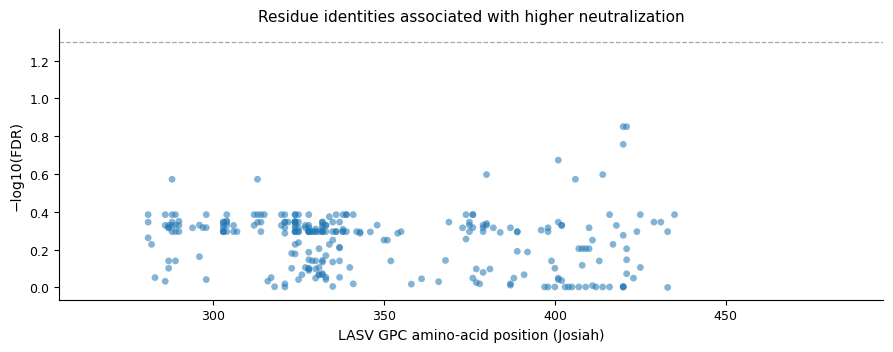

In [12]:
plot_df = residue_results.loc[residue_results['delta_median_neut'] > 0].copy()

fig, ax = plt.subplots(figsize=(9, 3.6))

if len(plot_df):
    y = -np.log10(plot_df['FDR_residue'].clip(lower=1e-300))
    ax.scatter(plot_df['position'], y, s=24, alpha=0.55, edgecolor='none')

    sig = plot_df['FDR_residue'] < 0.05
    ax.scatter(
        plot_df.loc[sig,'position'],
        -np.log10(plot_df.loc[sig,'FDR_residue'].clip(lower=1e-300)),
        s=42, edgecolor='black', linewidth=0.6
    )

    for _, r in plot_df.loc[sig].iterrows():
        ax.text(
            r['position'], -np.log10(max(r['FDR_residue'],1e-300)) + 0.08,
            f"{r['aa']}{int(r['position'])}",
            ha='center', va='bottom', fontsize=7
        )

ax.axhline(-np.log10(0.05), color='0.65', lw=0.9, ls='--')
ax.set_xlim(REGION_START-5, REGION_END+5)
ax.set_xlabel('LASV GPC amino-acid position (Josiah)')
ax.set_ylabel('−log10(FDR)')
ax.set_title('Residue identities associated with higher neutralization')
fig.tight_layout()
fig.savefig(OUTDIR / 'mammarenavirus_GPC_residue_neutralization_landscape.svg', bbox_inches='tight')
fig.savefig(OUTDIR / 'mammarenavirus_GPC_residue_neutralization_landscape.pdf', bbox_inches='tight')
plt.show()

## 12. Sequence-by-position heatmap for the strongest peptide variants

In [13]:
# Build a reference-coordinate character matrix for unique mapped target peptides.
positions = list(range(REGION_START, REGION_END+1))
seq_rows=[]
for _, r in region_peps.iterrows():
    d = {p: aa for p, aa in r['residue_pairs'] if REGION_START <= p <= REGION_END}
    row = {'peptide': r['peptide'], 'species': r['species'], 'ref_start': r['ref_start'], 'ref_end': r['ref_end']}
    row.update({p: d.get(p, '') for p in positions})
    seq_rows.append(row)

aligned_matrix = pd.DataFrame(seq_rows)

# Merge peptide-level neutralization association so strongest positive peptides can be inspected first.
if len(peptide_assoc):
    aligned_matrix = aligned_matrix.merge(
        peptide_assoc[['peptide','delta_median_neut','FDR_peptide']],
        on='peptide', how='left'
    )
    aligned_matrix = aligned_matrix.sort_values(['FDR_peptide','delta_median_neut'], ascending=[True,False], na_position='last')

# Display a compact table around candidate residues if any; otherwise around the target region start.
if len(positive_residues):
    cand_pos = sorted(positive_residues['position'].unique())
    lo = max(REGION_START, min(cand_pos)-8)
    hi = min(REGION_END, max(cand_pos)+8)
else:
    lo, hi = REGION_START, min(REGION_START+80, REGION_END)

show_cols = ['species','peptide','delta_median_neut','FDR_peptide'] + list(range(lo,hi+1))
display(aligned_matrix[[c for c in show_cols if c in aligned_matrix.columns]].head(40))

,species,peptide,delta_median_neut,FDR_peptide,260,261,262,263,264,265,...,331,332,333,334,335,336,337,338,339,340
26,Mammarenavirus lassaense,AZI96412.1|precursor|Mammarenavirus_lassaense|...,21.536470,0.000002,,,,,,,...,,,,,,,,,,
24,Mammarenavirus lassaense,AZI96059.1|precursor|Mammarenavirus_lassaense|...,20.969990,0.000018,,,,,,,...,,,,,,,,,,
27,Mammarenavirus lassaense,AZI96476.1|precursor|Mammarenavirus_lassaense|...,18.444158,0.000033,,,,,,,...,,,,,,,,,,
29,Mammarenavirus lassaense,AZI96488.1|precursor|Mammarenavirus_lassaense|...,18.598790,0.000084,,,,,,,...,,,,,,,,,,
52,Mammarenavirus choriomeningitidis,WDY78991.1|precursor|Mammarenavirus_choriomeni...,21.288375,0.000086,,,,,,,...,E,S,A,L,H,L,,,,
18,Mammarenavirus lassaense,AHC95553.1|precursor|Mammarenavirus_lassaense|...,19.049108,0.000096,,,,,,,...,,,,,,,,,,
64,Yunnan rodent mammarenavirus 1,XOB76283.1|precursor|Yunnan_rodent_mammarenavi...,18.598790,0.000110,,,,,,,...,N,K,S,L,N,L,I,T,K,A
23,Mammarenavirus lassaense,ANH09740.1|precursor|Mammarenavirus_lassaense|...,20.780602,0.000147,,,,,,,...,Q,M,N,I,Q,L,I,N,K,A
57,Mammarenavirus lassaense,XBA96065.1|precursor|Mammarenavirus_lassaense|...,20.490105,0.000147,,,,,,,...,Q,M,S,I,Q,L,I,N,K,A
40,Wenzhou Suncus murinus mammarenavirus 1,UBB42231.1|precursor|Wenzhou_Suncus_murinus_ma...,19.880792,0.000147,,,,,,,...,N,K,S,T,N,L,I,T,S,A


## 13. Export results

The most important tables are:
- `peptide_assoc`: mammarenavirus GPC peptide-level association with neutralization.
- `residue_results`: all tested residue identities.
- `positive_residues`: FDR-significant residue identities associated with higher neutralization.
- `residue_sensitivity`: participant-collapsed sensitivity analysis.
- `aligned_matrix`: mapped natural sequence variation in the target GPC window.

In [14]:
peptide_assoc.to_csv(OUTDIR / 'mammarenavirus_GPC_peptide_neutralization_associations.csv', index=False)
residue_results.to_csv(OUTDIR / 'mammarenavirus_GPC_residue_neutralization_associations.csv', index=False)
positive_residues.to_csv(OUTDIR / 'mammarenavirus_GPC_positive_residue_candidates.csv', index=False)
residue_sensitivity.to_csv(OUTDIR / 'mammarenavirus_GPC_residue_sensitivity_analysis.csv', index=False)
aligned_matrix.to_csv(OUTDIR / 'mammarenavirus_GPC_aligned_sequence_matrix.csv', index=False)

print('Saved outputs to:', OUTDIR)

Saved outputs to: output_figures/residue_neutralization


## Interpretation guardrails

A strong candidate residue should ideally satisfy several criteria:

- sufficient natural amino-acid variation at that aligned position;
- enough reactive survivors carrying both the candidate and alternative states;
- positive neutralization effect (`delta_median_neut > 0`);
- survives residue-level FDR correction;
- directionally agrees in the participant-collapsed sensitivity analysis;
- lies within/near the LASV GPC neutralization-associated peptide cluster discovered independently.

Even then, describe it as a **neutralization-associated residue identity or motif**. To call it *critical for neutralization*, follow up experimentally with substitutions/competition or monoclonal-antibody mapping.